# Análisis Exploratorio de Datos: Titanic

En esta actividad usaremos la base de datos de pasajeros del Titanic para practicar **análisis exploratorio de datos (EDA)**.

El objetivo no es hacer la mayor cantidad posible de gráficos, sino aprender a **usar los datos para responder preguntas**.

## Pregunta de investigación

> **¿Qué características de los pasajeros estaban asociadas con la supervivencia en el Titanic?**


## Librerías de visualización
### Matplotlib

Matplotlib tiene dos métodos para crear una figura, uno directo y otro enfocado a objetos.
Algunos links de interés:

- Argumentos que reciben matplotlib: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html
- Más opciones de gráficos en https://matplotlib.org/2.0.2/gallery.html
- Para una lista de colores disponibles en Matplotlib, https://matplotlib.org/stable/gallery/color/named_colors.html
- Explicación de plt y ax https://towardsdatascience.com/what-are-the-plt-and-ax-in-matplotlib-exactly-d2cf4bf164a9


### Seaborn
Proporciona una interfaz de alto nivel para dibujar gráficos estadísticos atractivos e informativos. A diferencia de Matplotlib, ésta no viene por defecto en Pandas.
Galería de gráficos: https://seaborn.pydata.org/examples/index.html

Otro link útil para visualizaciones en Python: https://python-graph-gallery.com/


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_style("white")


## Carga de los datos

Cada fila de la base de datos corresponde a **un pasajero**.

Las principales características disponibles son:

- `Survived`: supervivencia, 0 = no, 1 = sí
- `Pclass`: clase del pasajero, 1 = primera, 2 = segunda, 3 = tercera
- `Sex`: sexo
- `Age`: edad
- `SibSp`: número de hermanos/as o cónyuges a bordo
- `Parch`: número de padres o hijos a bordo
- `Ticket`: identificador del pasaje
- `Fare`: tarifa pagada
- `Cabin`: cabina
- `Embarked`: puerto de embarque, C = Cherbourg, Q = Queenstown, S = Southampton


In [ ]:
titanic = pd.read_csv("titanic_semana_02.csv")
titanic.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


#### **cuáles variables son numéricas y cuáles son categóricas?**



# Parte 1: Comprender la muestra

## ¿Quiénes eran los pasajeros del Titanic?

Antes de estudiar la supervivencia, necesitamos comprender a quiénes representan los datos.

Preguntas iniciales:

- ¿Cuántos pasajeros hay?
- ¿Qué características contiene la base de datos?
- ¿Cómo se distribuyen por sexo y clase?
- ¿Qué edades aparecen?
- ¿Cuánto pagaron por sus pasajes?
- ¿Viajaban solos o acompañados?
- ¿Desde qué puerto embarcaron?

Revise la estructura general de la tabla: dimensión, columnas, estadística básica, etc.

### Ejemplo de gráfico: pasajeros por sexo

Para una característica categórica podemos comenzar contando cuántos pasajeros pertenecen a cada grupo.


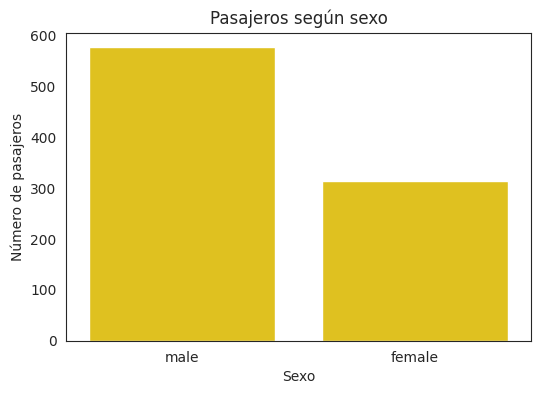

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(data=titanic, x="Sex", color="gold")

plt.xlabel("Sexo")
plt.ylabel("Número de pasajeros")
plt.title("Pasajeros según sexo")

plt.show()


### Ahora usted

**1. Grafique la cantidad de pasajeros según `Pclass`.**

- Qué clase contiene más pasajeros? La clase que contiene más pasajeros es la tercera clase, con 491 pasajeros.
- La muestra está balanceada entre las tres clases? La muestra está balanceada entre las clases 1 y 2, hay una diferencia de solo 16%. Sin embargo, la muestra no está balanceada con la última clase. Hay más de dos veces más pasajeros en la clase 3 que en las otras.


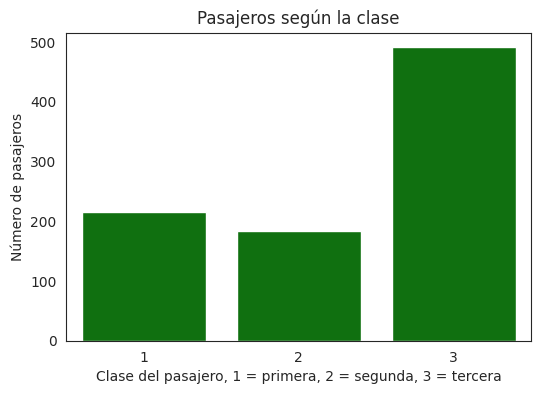

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(data=titanic, x="Pclass", color="green")

plt.xlabel("Clase del pasajero, 1 = primera, 2 = segunda, 3 = tercera")
plt.ylabel("Número de pasajeros")
plt.title("Pasajeros según la clase")

plt.show()

In [ ]:
print("Número de pasajeros en cada clase :")
print(titanic["Pclass"].value_counts())

Número de pasajeros en cada clase :
Pclass
3    491
1    216
2    184
Name: count, dtype: int64


**2. Explore la distribución de `Age` con un histograma.**

Pruebe, por ejemplo, con 15, 30 y 50 bins.

- ¿Qué edades son más frecuentes? Las edades más frecuentes son los jóvenes adultos de 18 a 32 años.
- ¿La distribución parece simétrica? La distribución no parece simétrica, pero es normal. Las edades varían entre 0 y 80 y el máximo no es 40, sino más o menos 25. Entonces es normal obtener una gaussiana asimétrica.
- ¿El número de bins cambia su interpretación? El número de bins no cambia las edades más frecuentes o la distribución, pero cuando hay más precisión vemos que algunas edades son menos comunes, hay una especie de alternancia que podemos ver con 50 bins pero no con 15.


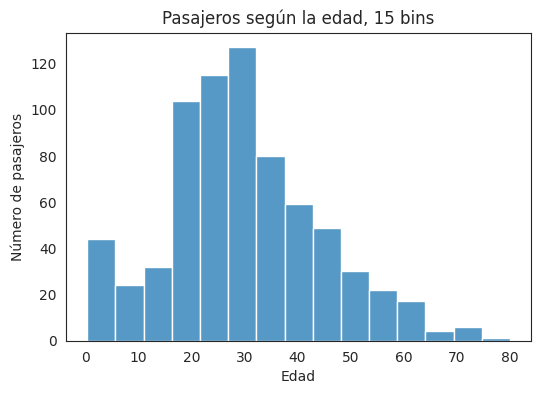

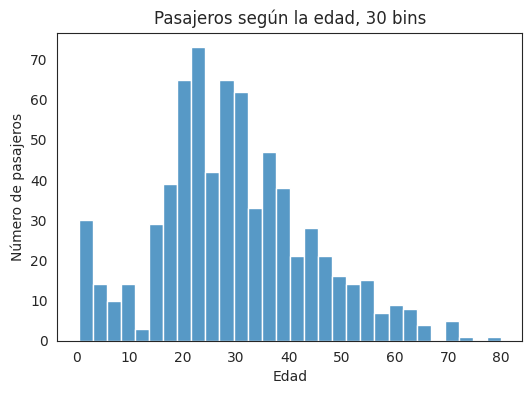

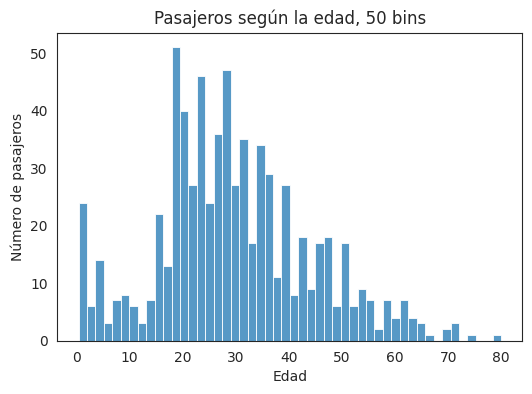

In [ ]:
plt.figure(figsize=(6,4))
sns.histplot(data=titanic, x="Age", bins=15)

plt.xlabel("Edad")
plt.ylabel("Número de pasajeros")
plt.title("Pasajeros según la edad, 15 bins")
plt.show()

plt.figure(figsize=(6,4))
sns.histplot(data=titanic, x="Age", bins=30)

plt.xlabel("Edad")
plt.ylabel("Número de pasajeros")
plt.title("Pasajeros según la edad, 30 bins")
plt.show()

plt.figure(figsize=(6,4))
sns.histplot(data=titanic, x="Age", bins=50)

plt.xlabel("Edad")
plt.ylabel("Número de pasajeros")
plt.title("Pasajeros según la edad, 50 bins")
plt.show()

**3. Explore la distribución de `Fare`.**

Puede usar un histograma o un boxplot.

- ¿La distribución es simétrica? La distribution no es symetrica.
- ¿Existen tarifas muy superiores al resto? Hay muchas personas que pagan menos de 170 y muy pocas más. Para visualizar los resultados, hice 3 gráficos. Uno con todas las tarifas pero en escala log para ver todos los datos, y dos histogramas clásicos: uno para las tarifas inferiores a 170, y otro para las tarifas superiores.
- ¿Qué podría significar esto? Vemos que las tarifas inferiores a 170 disminuyen de manera exponencial, lo que es normal porque mientras más caro es el viaje, menos personas hay. Para las tarifas superiores, no hay suficiente data para sacar conclusiones. Podemos suponer que hay, en la primera clase, clases excepcionales que son excepcionalmente caras.


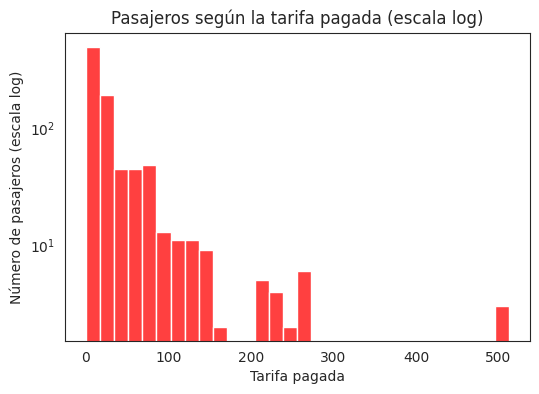

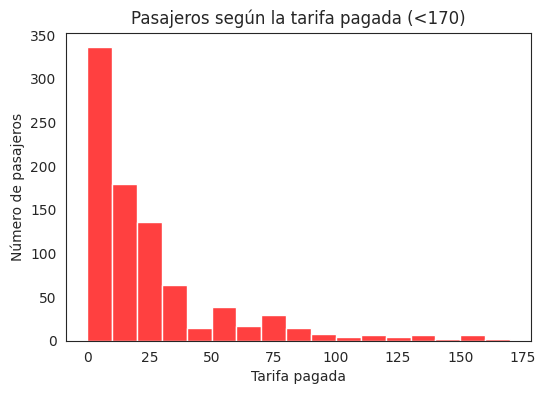

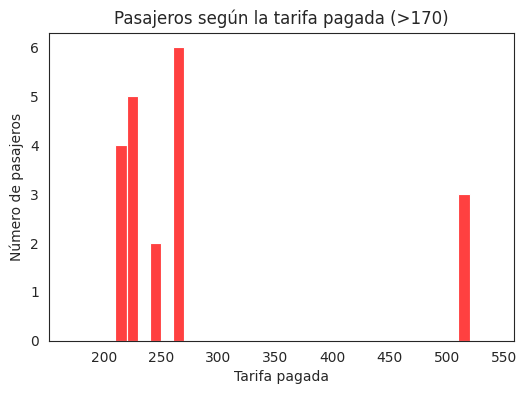

In [ ]:
plt.figure(figsize=(6,4))
sns.histplot(data=titanic, x="Fare", bins=30, color="red")
plt.yscale("log")

plt.xlabel("Tarifa pagada")
plt.ylabel("Número de pasajeros (escala log)")
plt.title("Pasajeros según la tarifa pagada (escala log)")
plt.show()

plt.figure(figsize=(6,4))
bins_auto = np.arange(0, 171, 10)
sns.histplot(data=titanic, x="Fare", bins=bins_auto, color="red")

plt.xlabel("Tarifa pagada")
plt.ylabel("Número de pasajeros")
plt.title("Pasajeros según la tarifa pagada (<170)")
plt.show()

plt.figure(figsize=(6,4))
bins_auto = np.arange(170, 550, 10)
sns.histplot(data=titanic, x="Fare", bins=bins_auto, color="red")

plt.xlabel("Tarifa pagada")
plt.ylabel("Número de pasajeros")
plt.title("Pasajeros según la tarifa pagada (>170)")
plt.show()


# Parte 2: Calidad de los datos

## ¿Qué información falta y por qué podría importar?

Antes de interpretar cualquier patrón debemos revisar la calidad de los datos.

Nos interesa detectar:

- valores faltantes
- características con mucha información incompleta
- valores extremos o sospechosos
- decisiones de limpieza que puedan cambiar nuestras conclusiones


In [ ]:
datos_faltantes = titanic.isnull().sum()
datos_faltantes


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


### Ejemplo de gráfico: valores faltantes

Podemos visualizar cuántos datos faltan en cada característica.


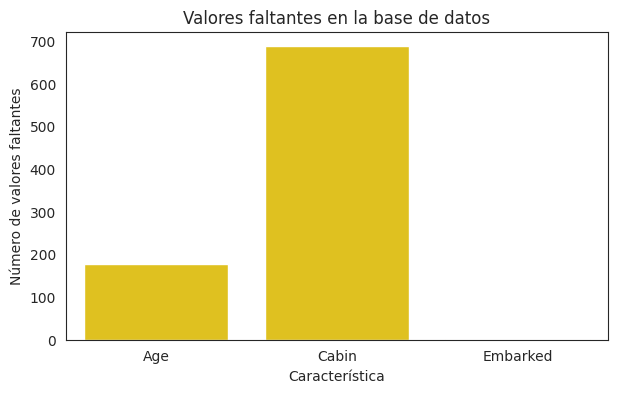

In [ ]:
faltantes = datos_faltantes[datos_faltantes > 0]

plt.figure(figsize=(7,4))

sns.barplot(x=faltantes.index, y=faltantes.values, color='gold')

plt.xlabel("Característica")
plt.ylabel("Número de valores faltantes")
plt.title("Valores faltantes en la base de datos")

plt.show()


### Ahora usted

Observe especialmente `Age`, `Cabin` y `Embarked`.

**1. Compare la media y la mediana de `Age`.**

- Son similares? Los dos valores son similares. La media es un poco más grande que la mediana, pero es normal porque en el histograma de las edades podemos ver que hay más edades mayores a la media que edades más pequeñas (porque no es posible tener menos de 0 años, mientras que es posible tener más de 56...).
- Es la media una buena representación de una edad típica? Pienso que, por la edad, la mediana es una buena representación. Además, es un número redondo fácil de manipular.


In [ ]:
media = titanic["Age"].mean()
mediana = titanic["Age"].median()
print("\nMedia:", media)
print("\nMediana:", mediana)



Media: 29.69911764705882

Mediana: 28.0


**2. La edad tiene datos faltantes.**

- Le parece razonable reemplazar todas las edades faltantes por la media? No me parece razonable porque las edades son más dispersas, hay una gran desviación estándar y, entonces, podría falsear los datos.
- Qué problema podría producir esa decisión en la distribución de edades? Aparecería un inmenso pic a los 28, tres veces más grande que los otros.
- Qué otra estrategia consideraría? Podemos suprimir los datos sobre las personas, pero es como el 25% de los datos y, entonces, pienso que sería una pérdida demasiado grande. Pienso que la mejor solución es no estudiar a estos pasajeros cuando discutamos de la edad, pero sí estudiarlos cuando discutamos de otras cosas.


**3. `Cabin` tiene una gran cantidad de valores faltantes.**

- Intentaría rellenarlos? Una vez más, creo que no, no sería pertinente completar los datos con valores ficticios.
- Eliminaría la característica? Pienso que podriamos eliminar la caracteristica como falta mas de 70% de los datos.
- Podría el hecho de conocer o no la cabina contener información por sí mismo? Ademas, la sola informaciones de la cabine no es realmente util; sería útil conocer la ubicación de esta (primer piso, segundo piso, adelante, detrás...)

No hay una única respuesta correcta: justifique su decisión.


**4. `Embarked` tiene pocos datos faltantes.**

- Qué estrategia simple usaría en este caso? Lo más simple sería suprimir los datos de los dos pasajeros a los que les falta el dato "embarked", porque hay solo dos personas.
- Por qué el tratamiento puede ser distinto al de `Cabin`? El tratamiento que elegiría es distinto porque la cantidad de datos faltantes es completamente diferente. Faltan solo 2 "Embarked", mientras que falta el 70% de las "Cabin".


# Parte 3: Explorar relaciones entre características

## ¿Cómo se relacionan las características de los pasajeros?

Después de estudiar las características individualmente, podemos comenzar a buscar estructura en los datos.

Preguntas posibles:

- La tarifa pagada está relacionada con la clase?
- Las edades son similares en todas las clases?
- Quiénes viajaban acompañados?
- Hay características que contienen información parcialmente similar?



### Ejemplo de gráfico: tarifa según clase

Un boxplot permite comparar la distribución de una característica numérica entre distintos grupos.


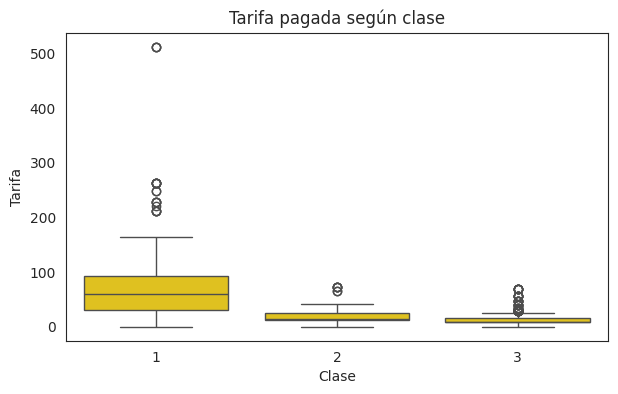

In [ ]:
plt.figure(figsize=(7,4))

sns.boxplot(data=titanic, x="Pclass", y="Fare", color='gold')

plt.xlabel("Clase")
plt.ylabel("Tarifa")
plt.title("Tarifa pagada según clase")

plt.show()


### Preguntas

- La tarifa parece estar relacionada con la clase? La tarifa parece relacionada con la clase. Los pasajeros de la primera clase pagan más que la segunda y más que la última.
- Hay dispersión dentro de cada clase? La clase con más dispersión es la primera clase. Pienso que es porque existen varios tipos de cabina con diferentes niveles y diferentes precios. Hay también muchas personas que pagan un precio superior al noveno decil en la tercera clase.
- Existen valores extremos? Existen valores extremos para la primera.
- Diría que `Fare` y `Pclass` contienen exactamente la misma información? No porque, por ejemplo, hay personas que pagan menos en la primera o segunda clase que en la tercera. Los "Fare" son más precisos para conocer el nivel social de los pasajeros. También la clase es útil porque probablemente las cabinas o los lugares de vida común estaban organizados en el espacio por clase.

### Ahora usted

**1. Compare la distribución de edad entre las tres clases.**

Use un gráfico que permita comparar las distribuciones.

- Los pasajeros tienen edades similares en todas las clases? Los pasajeros tienen edades similares en todas las clases. Especialmente, hay una cantidad similar de niños en las tres clases.
- Qué diferencias observa? Podemos observar que los jóvenes son más en la tercera clase, y los adultos y adultos mayores, más en la primera. Es normal porque las clases más caras necesitan un público más rico y, por lo tanto, a menudo más viejo. Sin embargo, hay algunos adultos mayores en las clases 2 y 3, pero no son muchos.


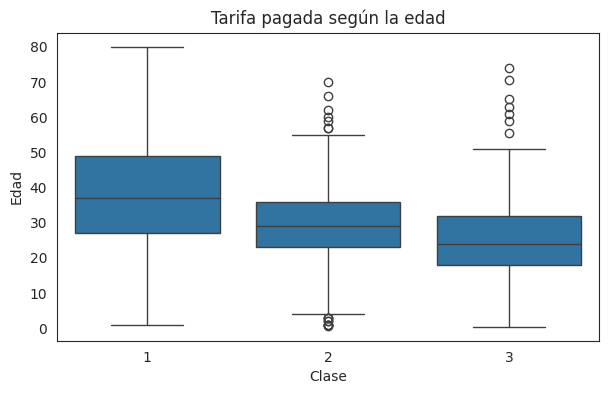

In [ ]:
plt.figure(figsize=(7,4))

sns.boxplot(data=titanic, x="Pclass", y="Age")

plt.xlabel("Clase")
plt.ylabel("Edad")
plt.title("Tarifa pagada según la edad")

plt.show()



**2. Las características `SibSp` y `Parch` contienen información sobre familiares a bordo.**

Construya una nueva característica llamada `Familia`, que represente el número total de personas del grupo familiar incluyendo al propio pasajero:

\[
Familia = SibSp + Parch + 1
\]


In [ ]:
titanic["Familia"] = titanic["SibSp"] + titanic["Parch"] + 1

# Revise el resultado
titanic["Familia"].value_counts()


,count
Familia,
1,537
2,161
3,102
4,29
6,22
5,15
7,12
11,7
8,6


**3. Explore la nueva característica `Familia`.**

- La mayoría de los pasajeros viajaba sola o acompañada? La mayoría de los pasajeros viajaba sola (~60%).
- Hay grupos familiares muy grandes? Sí hay grupos grandes. El número de grupos disminuye con el tamaño del grupo y entonces las grandes familias son menos frecuentes que las pequeñas. Un número sorprendente es que hay siete familias de 11 personas, mientras que no hay ninguna de 9, 10 o más de 11.
- Cambiaría su interpretación si solo mirara `SibSp` o `Parch` por separado? Si miramos los dos separados, vemos que es más común viajar con uno o dos padres o hijos, pero casi nunca más. Las grandes familias vienen del número de hermanos/as que puede ser de ocho personas.


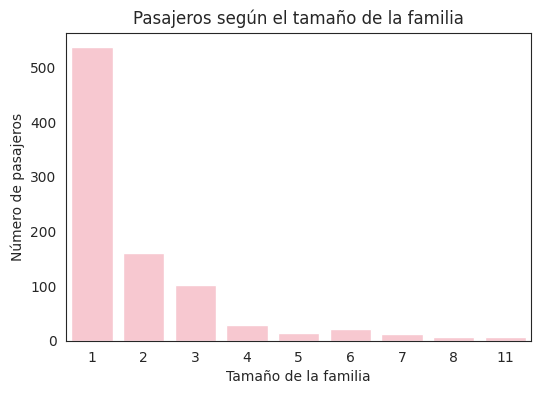

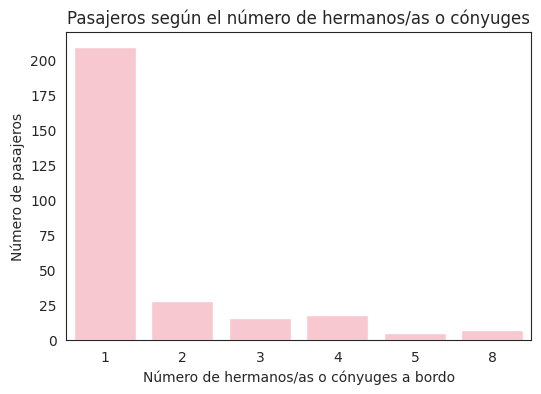

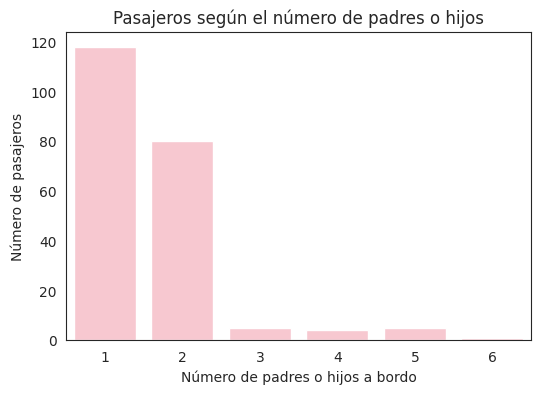

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(data=titanic, x="Familia", color="pink")

plt.xlabel("Tamaño de la familia")
plt.ylabel("Número de pasajeros")
plt.title("Pasajeros según el tamaño de la familia")
plt.show()

plt.figure(figsize=(6,4))
sns.countplot(data=titanic[titanic["SibSp"] != 0], x="SibSp", color="pink")

plt.xlabel("Número de hermanos/as o cónyuges a bordo")
plt.ylabel("Número de pasajeros")
plt.title("Pasajeros según el número de hermanos/as o cónyuges")
plt.show()

plt.figure(figsize=(6,4))
sns.countplot(data=titanic[titanic["Parch"] != 0], x="Parch", color="pink")

plt.xlabel("Número de padres o hijos a bordo")
plt.ylabel("Número de pasajeros")
plt.title("Pasajeros según el número de padres o hijos")
plt.show()

# Parte 4: Investigar la supervivencia

## ¿Qué características estaban asociadas con la supervivencia?

Ahora incorporaremos `Survived`, la variable que queremos comprender.

Investigaremos si la supervivencia está asociada con características como:

- sexo
- clase
- edad
- tamaño del grupo familiar


### Ejemplo de gráfico: supervivencia según sexo

Como `Survived` toma valores 0 y 1, su promedio dentro de un grupo corresponde a la **fracción de pasajeros que sobrevivió**.

`seaborn.barplot` calcula por defecto la media de la variable del eje vertical.


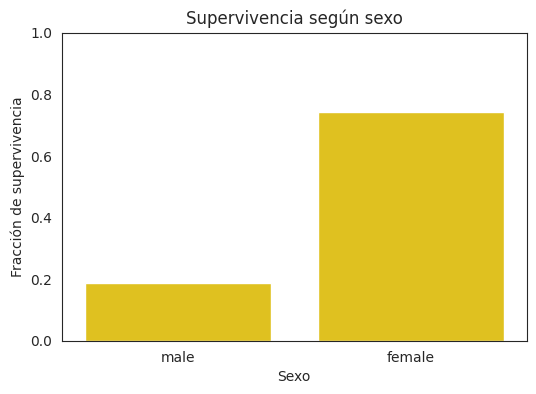

In [ ]:
plt.figure(figsize=(6,4))

sns.barplot(data=titanic, x="Sex", y="Survived", errorbar=None, color='gold')

plt.xlabel("Sexo")
plt.ylabel("Fracción de supervivencia")
plt.title("Supervivencia según sexo")
plt.ylim(0,1)

plt.show()


### Preguntas

- La fracción de supervivencia es similar para hombres y mujeres? La fracción de supervivencia es más diferente para hombres y mujeres. Las mujeres sobrevivían cuatro veces más que los hombres.
- Podemos concluir a partir de este gráfico por qué existe la diferencia? No podemos concluir el origen de esta diferencia por este gráfico, pero por la historia que creo, dice que las mujeres fueron embarcadas prioritariamente en los botes de rescate

### Ahora usted

**1. Explore la supervivencia según `Pclass`.**

- Hay diferencias entre las tres clases? Sí, hay una gran diferencia entre las tres clases.
- Existe una tendencia? Cuanto mejor es la clase, mejores son los porcentajes de supervivencia. Hay finalmente una diferencia de simple a doble entre la 3 y la 2, y casi de simple a triple entre la 3 y la 1.


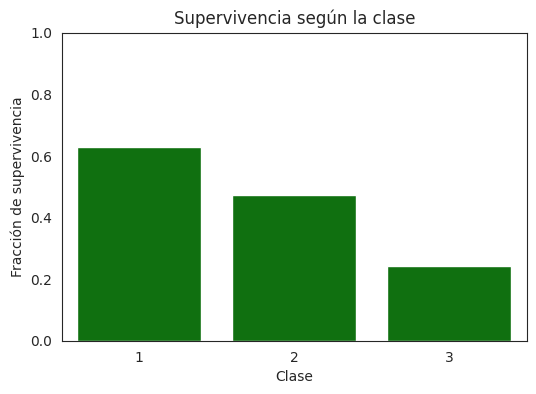

In [ ]:
plt.figure(figsize=(6,4))
sns.barplot(data=titanic, x="Pclass", y="Survived", errorbar=None, color="green")

plt.xlabel("Clase")
plt.ylabel("Fracción de supervivencia")
plt.title("Supervivencia según la clase")
plt.ylim(0,1)
plt.show()


**2. Explore la supervivencia según edad.**

Puede comparar las distribuciones de edad de quienes sobrevivieron y quienes no sobrevivieron.

- La edad parece estar asociada con supervivencia? No hay una gran correlación entre la edad y la supervivencia
- Hay algún grupo de edad que llame particularmente su atención? Sin embargo, se puede ver en este gráfico que la supervivencia de los niños es mucho mejor, incluso es del 100% en los más pequeños.


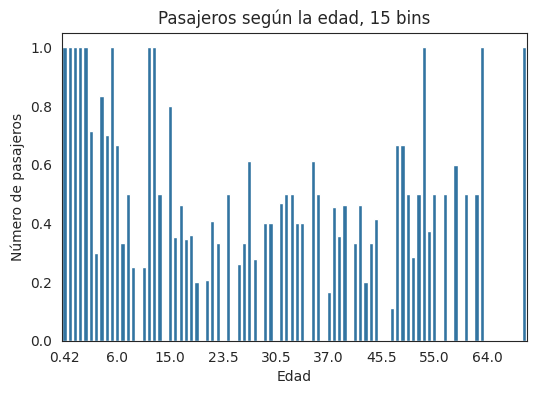

In [ ]:
plt.figure(figsize=(6,4))
sns.barplot(data=titanic, x="Age", y="Survived", errorbar=None)
plt.xticks([0, 10, 20, 30, 40, 50, 60, 70, 80])

plt.xlabel("Edad")
plt.ylabel("Fracción de supervivencia")
plt.title("Supervivencia según la edad")
plt.ylim(0,1)
plt.show()



**3. Explore la supervivencia según `Familia`.**

- Viajar solo parece favorable o desfavorable? Viajar solo parece favorable, pero no más que viajar con una gran familia.
- La relación parece simple? Los resultados no son tan simples porque al inicio la supervivencia aumenta con el tamaño de la familia, pero finalmente cae cuando la familia es demasiado grande (>4 personas).
- Qué ocurre con los grupos familiares grandes? En las grandes familias, la supervivencia es mas debil que en las familias pequeñas y que en los pasajeros que viajan solos. Hay finalmente 0 supervivientes en las familias de 8 y 11.


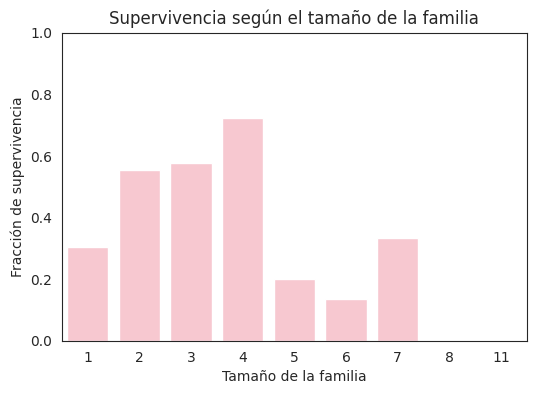

In [ ]:
plt.figure(figsize=(6,4))
sns.barplot(data=titanic, x="Familia", y="Survived", errorbar=None, color="pink")

plt.xlabel("Tamaño de la familia")
plt.ylabel("Fracción de supervivencia")
plt.title("Supervivencia según el tamaño de la familia")
plt.ylim(0,1)
plt.show()

# Parte 5: Agregar contexto

## ¿Cambia una relación cuando consideramos otra característica?

Una relación global puede esconder comportamientos diferentes dentro de la muestra.

Ya estudiamos por separado:

- `Pclass` y supervivencia
- `Sex` y supervivencia

Ahora podemos preguntar:
 **¿La relación entre clase y supervivencia es igual para hombres y mujeres?**

Esta es una forma sencilla de análisis multivariado: consideramos varias características al mismo tiempo.


### Ejemplo de gráfico: clase, sexo y supervivencia


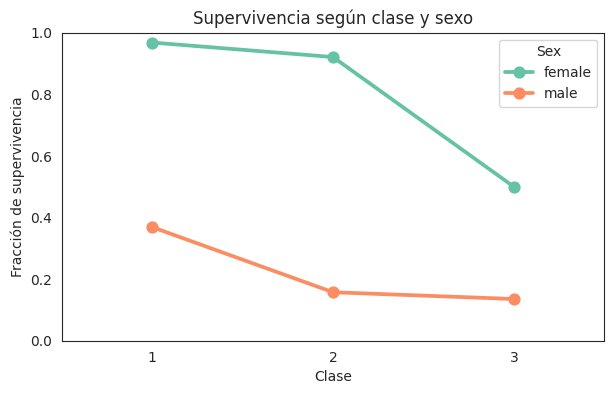

In [ ]:
plt.figure(figsize=(7,4))

sns.pointplot(data=titanic,
              x="Pclass",
              y="Survived",
              hue="Sex",
              palette="Set2",
              errorbar=None)

plt.xlabel("Clase")
plt.ylabel("Fracción de supervivencia")
plt.title("Supervivencia según clase y sexo")
plt.ylim(0,1)

plt.show()


### Preguntas sobre el ejemplo

- La relación entre clase y supervivencia es igual para hombres y mujeres? La relación no es igual.
- Qué información se perdía cuando mirábamos solamente `Pclass`? Cuando solo vimos Pclass, no vimos que los hombres de segunda clase no sobreviven mucho más que los hombres de tercera clase. No vimos también que las mujeres de primera y segunda clase sobreviven casi todas.
- Qué información se perdía cuando mirábamos solamente `Sex`? Si solo miramos el sexo, no vimos también que las mujeres de primera y segunda clase sobreviven casi todas.
- Hay algún grupo particularmente favorecido o desfavorecido? Los grupos favorecidos son las mujeres de clase 1 y 2, y los desfavorecidos son los hombres de clase 2 y 3.



### Ahora usted

**1. Cree una característica `Persona` con tres categorías:**

- `mujer`
- `hombre`
- `niño/a`

Considere como niño/a a un pasajero menor de 16 años.


In [ ]:
conditiones = [titanic["Age"] < 16, titanic["Sex"] == "male", titanic["Sex"] == "female"]
categorias = ["niño/a", "hombre", "mujer"]
titanic["Persona"] = np.select(conditiones, categorias, default="bug")

titanic["Persona"].value_counts()


,count
Persona,
hombre,537
mujer,271
niño/a,83


**2. Explore la supervivencia según `Persona` y `Pclass`.**

- Los niños presentan el mismo patrón que los adultos? Los niños presentan un patrón similar a las mujeres en cantidad, y a todos los adultos en evolución, pero, al contrario de los adultos, los niños de segunda clase sobreviven mejor que los niños de primera clase.
- La clase sigue siendo importante dentro de cada grupo? Sí, la clase sigue siendo importante. La supervivencia siempre es mayor en la primera que en la tercera. Para la segunda, depende.
- Qué combinación de características parece asociarse con la mayor supervivencia? La combinación mujer/niños parece dar la mayor supervivencia..


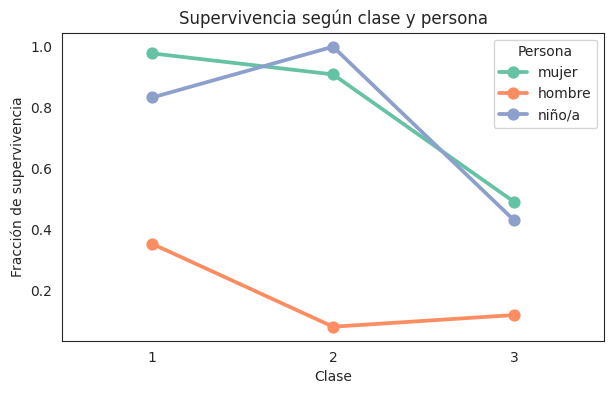

In [ ]:
plt.figure(figsize=(7,4))

sns.pointplot(data=titanic,
              x="Pclass",
              y="Survived",
              hue="Persona",
              palette="Set2",
              errorbar=None)

plt.xlabel("Clase")
plt.ylabel("Fracción de supervivencia")
plt.title("Supervivencia según clase y persona")

plt.show()


**3. Elija una relación adicional para explorar incorporando una tercera característica.**

Algunas ideas:

- edad + sexo + supervivencia;
- tamaño de familia + clase + supervivencia;
- puerto de embarque + clase + supervivencia.

No necesita crear una figura complicada. El objetivo es responder una pregunta concreta.

**Escriba primero la pregunta que quiere investigar y luego construya el gráfico.**


¿La relación entre el tamaño de la familia y la supervivencia es la misma en las diferentes clases? Para las pequeñas familias, la relación es la misma entre las diferentes clases. La supervivencia aumenta cuando el tamaño de la familia aumenta. Después depende. Para la clase 1 es inestable, para la clase 2 continúa aumentando y después se estabiliza, y para la clase 3 cae. También descubrimos que las familias de más de 6 personas están todas en tercera clase.

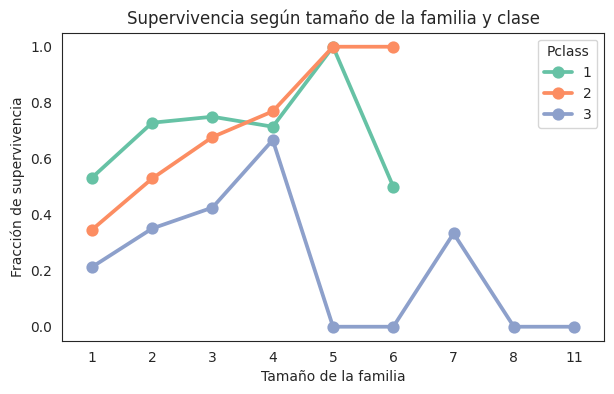

In [ ]:
plt.figure(figsize=(7,4))

sns.pointplot(data=titanic,
              x="Familia",
              y="Survived",
              hue="Pclass",
              palette="Set2",
              errorbar=None)

plt.xlabel("Tamaño de la familia")
plt.ylabel("Fracción de supervivencia")
plt.title("Supervivencia según tamaño de la familia y clase")
plt.show()


# Parte 6: Conclusión

## ¿Qué podemos concluir?

El EDA no termina cuando encontramos diferencias entre grupos.

Queremos distinguir entre:

### Observación
Algo que vemos directamente en los datos.

### Interpretación
Cómo describimos ese patrón.

### Hipótesis
Una explicación posible que debería ser evaluada con más información.

Por ejemplo:

> **Observación:** las mujeres presentan una mayor fracción de supervivencia que los hombres.

- **Podemos concluir, solo a partir de esta base de datos, que durante la evacuación se dio prioridad a mujeres y niños?**
- **Qué información adicional necesitaríamos para evaluar esa hipótesis?**
- **Qué otras explicaciones podrían producir el mismo patrón de supervivencia?**

## Síntesis del análisis

Revise todas las figuras construidas y responda:

### 1. ¿Quiénes eran los pasajeros del Titanic?

-   sexo: Hay aproximadamente el doble de hombres que de mujeres.
-   clase: La tercera clase era la más numerosa, con casi el doble de pasajeros que la primera o la segunda clase.
-   edad: La mayoría de los pasajeros eran adultos jóvenes entre los 18 y 32 años. Había también una cantidad considerable de niños, y la presencia de adultos mayores disminuía con la edad.
-   tamaño de familia: La mayoría de los pasajeros viajaba sola (~ 60%). Sin embargo, también existían grupos familiares de tamaño pequeño (2-4 personas) y algunas familias muy grandes (hasta 11 personas).

### 2. ¿Qué características estaban asociadas con la supervivencia?

-   sexo: Las mujeres sobrevivían aproximadamente cuatro veces más que los hombres.
-   clase: Los pasajeros de primera clase tenían la mayor probabilidad de sobrevivir, seguidos por los de segunda clase, y finalmente los de tercera clase con dos a tres veces menos de supervivientes.
-   edad: Los niños sobrevivían mejor que los adultos, especialmente los niños pequeños.
-   viajar solo o acompañado: Viajar con una familia pequeña era mejor que viajar solo, pero las familias muy grandes (5 o más personas) tenían una probabilidad de supervivencia inferior a la de los pasajeros que viajaban solos.

### 3. ¿Qué relaciones cambiaron al considerar varias características al mismo tiempo?

La supervivencia de la segunda clase cambia si vemos otros factores al mismo tiempo. Por ejemplo, los niños de segunda clase sobrevivían mejor que los de primera, mientras que los hombres de segunda clase no sobrevivían mucho mejor que los hombres de tercera clase.


### 4. ¿Encontró características que contienen información relacionada?

Sí, tarifa y clase están estrechamente relacionadas. En promedio, los pasajeros de clases más altas pagaban tarifas mayores.

### 5. ¿Qué resultado le pareció más inesperado?

Creo que lo más inesperado fue la baja supervivencia de las familias muy grandes.

-   Observación: Familias con 5+ miembros tenían una supervivencia cercana a cero.
-   Hipótesis: La dificultad logística de evacuar a un grupo tan grande y diverso pudo haber sido un factor crítico.

# Conclusión final

## ¿Cuál es el perfil del pasajero típico que sobrevivió?

A partir de **sus propios resultados**, escriba una conclusión breve que caracterice al pasajero con mayor probabilidad de haber sobrevivido en esta muestra.

Considere, cuando corresponda:

- sexo
- edad
- clase
- tamaño del grupo familiar
- otras características que hayan resultado relevantes

Su respuesta debe estar respaldada por las figuras que construyó.


### Escriba aquí su conclusión

El pasajero típico que sobrevivió son las mujeres y los niños de clase 1 y 2. También las familias pequeñas mejoraron la supervivencia.
